<a href="https://colab.research.google.com/github/Shriramn08/pk-modeling-fundamentals/blob/main/notebooks/01_explore_and_nca.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# Notebook 1: Data exploration and NCA

In [2]:
# SETUP CELL: run this first in EVERY notebook of the project
from google.colab import drive
drive.mount("/content/drive")             # connects your Google Drive

import os, sys
PROJ = "/content/drive/MyDrive/pk-modeling-fundamentals"   # project folder in Drive
FIG = f"{PROJ}/figures"                   # figures saved here survive the session
SRC = f"{PROJ}/src"                       # Day 9 code modules go here
for d in (FIG, SRC):
    os.makedirs(d, exist_ok=True)         # creates the folders if they don't exist
sys.path.append(SRC)                      # lets notebooks import your Day 9 modules
print("Ready:", PROJ)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Ready: /content/drive/MyDrive/pk-modeling-fundamentals


   rownames  Subject  time  conc
0         1        1  0.25  1.50
1         2        1  0.50  0.94
2         3        1  0.75  0.78
3         4        1  1.00  0.48
4         5        1  1.25  0.37
   rownames  Subject    Wt  Dose  time   conc
0         1        1  79.6  4.02  0.00   0.74
1         2        1  79.6  4.02  0.25   2.84
2         3        1  79.6  4.02  0.57   6.57
3         4        1  79.6  4.02  1.12  10.50
4         5        1  79.6  4.02  2.02   9.66


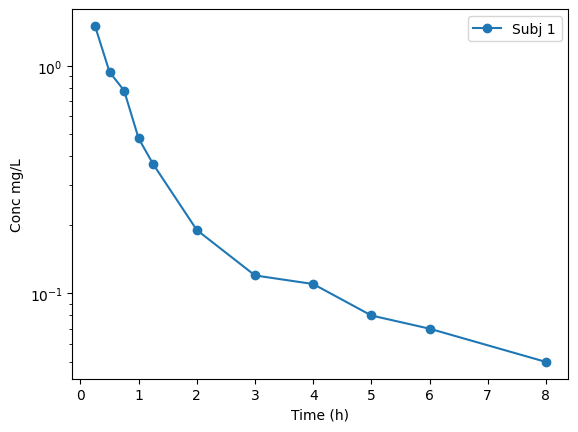

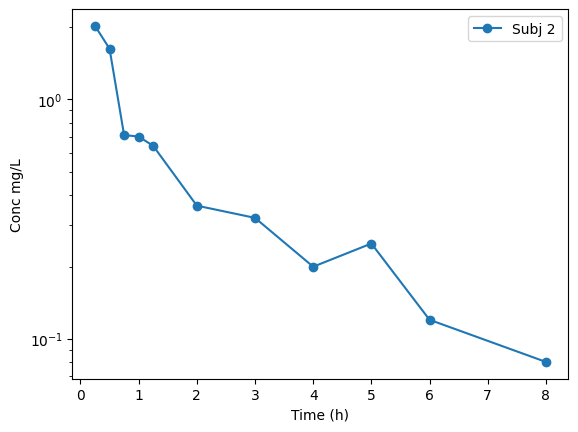

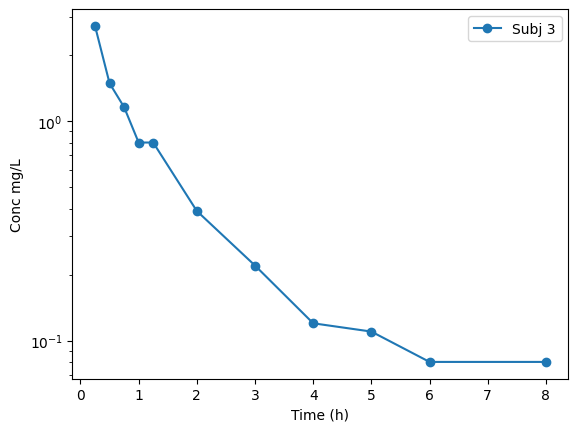

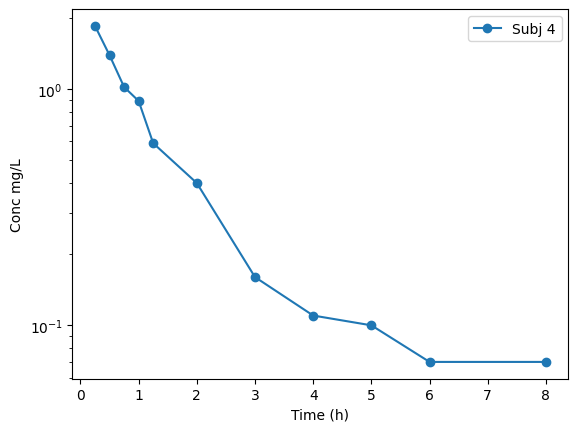

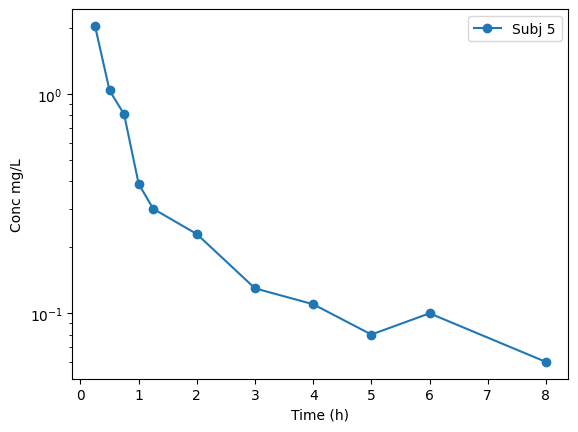

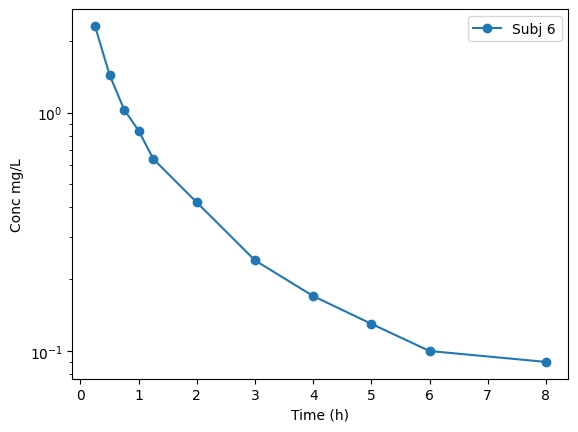

    AUC_inf    t_half         CL
1  1.869565  4.378127  13.372094
2  2.904411  1.955202   8.607598
3  3.472999  7.618109   7.198390
4  2.933150  6.801754   8.523260
5  2.203051  5.840352  11.347900
6  3.383111  6.156385   7.389649


<Figure size 640x480 with 0 Axes>

In [7]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy.integrate import trapezoid

indo = pd.read_csv("https://vincentarelbundock.github.io/Rdatasets/csv/datasets/Indometh.csv")
theo = pd.read_csv("https://vincentarelbundock.github.io/Rdatasets/csv/datasets/Theoph.csv")
theo = theo.rename(columns={"Time": "time"})   # Theoph uses a capital T; match Indometh
print(indo.head()); print(theo.head())   # always look at your columns first

#Semi-log plot: a straight line means 1-compartment, bends means >1 compartments
for sid, g in indo.groupby("Subject"):
  plt.semilogy(g["time"], g["conc"], "o-", label = f"Subj {sid}")
  plt.xlabel("Time (h)"); plt.ylabel("Conc mg/L");plt.legend(); plt.show()
  plt.savefig(f"{FIG}/raw_semilog.png", dpi=200)

DOSE_INDO = 25.0 #mg IV. Confirm in the dataset documentation (Kwan et al 1976)

def nca(t, c, dose, n_terminal=3):
    """Noncompartmental analysis: AUC by trapezoids plus extrapolation to infinity."""
    auc_0_t = trapezoid(c, t)                     # area under the observed curve
    slope = np.polyfit(t[-n_terminal:], np.log(c[-n_terminal:]), 1)[0]
    lam_z = -slope                                # terminal elimination rate constant (1/h)
    auc_inf = auc_0_t + c[-1] / lam_z             # extrapolate the tail to infinity
    return {"AUC_inf": auc_inf, "t_half": np.log(2) / lam_z, "CL": dose / auc_inf}

nca_table = pd.DataFrame(
    {sid: nca(g["time"].values, g["conc"].values, DOSE_INDO)
     for sid, g in indo.groupby("Subject")}).T
print(nca_table)


**Data Interpretation:**

1. The curves are bent and follow a rough shape of an exponential graph (ie. 2^-x). Since theres a bend we might need an extra compartment or two
2. Across the 6 subjects subject 1 had the highest Cl and subject 6 had the lowest CL. People seemed to differ by roughly 1 mg/L/hr
3. the halflife for subject 2 is way lower than for the others, but otherwise they look reasonable since they are less than the Cl except in subject 4

In [ ]:
from google.colab import drive
drive.mount('/content/drive')